
## The Finite Element Method (FEM) in 1D

This chapter introduces the Finite Element Method (FEM) as a numerical technique for solving two-point boundary value problems (differential equations). The core strategy involves three steps: 

1.  **Variational Formulation:** Rewriting the differential equation ("strong form") into an equivalent integral equation ("weak form").

2.  **Discretization:** Replacing the infinite-dimensional function space in the weak form with a finite-dimensional subspace of piecewise linear functions (the "Finite Element Space").

3.  **Linear System:** Deriving and solving a matrix system to find the approximate solution.

These notes are a summary of **Chapter 2** from the text *The FEM: Theory, Implementation, and Applications* by M.G. Larson.

---


### 1. The Model Problem

We begin with a model two-point boundary value problem: find a function $u(x)$ such that
$$
\begin{cases}
-u''(x) = f(x) \quad \text{for } x \in I = [0, L]\\
u(0) = 0, \quad u(L) = 0
\end{cases}
$$

This is the **"strong form"** of the problem.

#### 1.1 Variational Formulation ("Weak Form")

We derive the weak form by multiplying the DE by a **"test function"** $v$ and integrating over the domain $I$:
$$-\int_0^L u''(x)v(x) \,dx = \int_0^L f(x)v(x) \,dx$$

Next, we apply **integration by parts** to the left-hand side:
$$\int_0^L u'(x)v'(x) \,dx - [u'(x)v(x)]_0^L = \int_0^L f(x)v(x) \,dx$$

To simplify this, we introduce a **function space** $V_0$ for our test functions $v$ (and trial function $u$). This space contains functions that have square-integrable derivatives and satisfy the homogeneous boundary conditions:
$$V_0 = \{v \mid ||v||_{L^2} < \infty, ||v'||_{L^2} < \infty, \text{ and } v(0) = v(L) = 0\}$$

By choosing $v \in V_0$, the boundary terms $[u'v]_0^L$ automatically become zero, since $v(0)=0$ and $v(L)=0$.

This gives the final **variational formulation**: Find $u \in V_0$ such that
$$\int_I u'v' \,dx = \int_I fv \,dx \quad \forall v \in V_0$$

#### 1.2 Finite Element Approximation (Galerkin's Method)

The space $V_0$ is infinite-dimensional. We cannot solve this problem directly. The FEM solution is to replace $V_0$ with a finite-dimensional subspace.

We choose $V_{h,0}$, the space of continuous piecewise linear functions that also satisfy the boundary conditions:
$$V_{h,0} = \{v \in V_h \mid v(0) = v(L) = 0\}$$

The basis for this space is the set of *interior* hat functions $$\{\phi_i\}_{i=1}^{n-1}.$$ We exclude $\phi_0$ and $\phi_n$ because they are non-zero at the boundaries.

The **Finite Element Method** is: Find $u_h \in V_{h,0}$ such that
$$\int_I u_h'v' \,dx = \int_I fv \,dx \quad \forall v \in V_{h,0}$$
This is known as a **Galerkin method** because the trial space ($V_{h,0}$) and test space ($V_{h,0}$) are the same.

#### 1.3 Derivation of the Linear System

To solve this, we write the unknown solution $u_h$ as a linear combination of its basis functions (an "ansatz"):
$$u_h(x) = \sum_{j=1}^{n-1} \xi_j \phi_j(x)$$
The $\xi_j$ are $n-1$ unknown coefficients.

The FEM equation must hold for *all* $v \in V_{h,0}$, so it must hold for each basis function $\phi_i$ ($i=1, ..., n-1$). We substitute the ansatz and test against each $\phi_i$:
$$\int_I \left( \sum_{j=1}^{n-1} \xi_j \phi_j' \right) \phi_i' \,dx = \int_I f \phi_i \,dx \quad \text{for } i=1, ..., n-1$$

By linearity of the integral, we can pull the sum and coefficients out:
$$\sum_{j=1}^{n-1} \left( \int_I \phi_i' \phi_j' \,dx \right) \xi_j = \int_I f \phi_i \,dx$$

This is an $(n-1) \times (n-1)$ linear system $A\xi = b$, where:

* **Stiffness Matrix ($A$):** $$A_{ij} = \int_I \phi_i' \phi_j' \,dx$$

* **Load Vector ($b$):** $$b_i = \int_I f \phi_i \,dx$$

* **Solution Vector ($\xi$):** The unknown coefficients $\xi_j$.

---


In [20]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

In [21]:

def interpolant_1d(x, f_vals, xe):
    """
    Piecewise linear (hat function) interpolant of f on [0, 1].
    Given a set of nodal points and a set of it values x and f, and given xe a finer mesh
        lenx(x) = n+1 is the number of points in the notal set x = [x_0,...,x_n]
        n = number of elements in wich the set is divided I_i = [x_i, x_i+1] i=0,...,n-1
    
    Inputs:
        x : set of nodal points
        f_vals : set of values of f at the nodal points of x
        xe : Fine mech where we evaluate the interpolant
    Returns:
        x : nodal coordinates
        I : interpolated values on a fine grid (for plotting)
    """

    n = len(x) - 1  # number of elements in which we divide the x axis
    I = np.zeros_like(xe) #Creamos un array de zeros que tiene la misma dim y estructura que xe 

    # Loop over each element and assemble piecewise linear interpolant 
    # Recorremos los intervalos en lo que hemos dividido x y vamos construyendo el interpolante I
    for i in range(n):
        # Element nodes
        xL, xR = x[i], x[i+1] # Valores en los extremos del intervalo
        fL, fR = f_vals[i], f_vals[i+1] #Función en los valores del extremo del intervalo
                                        #Queremos almacenar el valor del interpolante en cada uno de los valores de xe
        # Points in this element
        mask = (xe >= xL) & (xe <= xR) #Valores de xe que se encuentran en el intervalo I_i estudiado
        xi = xe[mask] #xe restingido al intervalo en el que estamos

        # Linear interpolation (hat functions)
        phiL = (xR - xi) / (xR - xL)
        phiR = (xi - xL) / (xR - xL)

        I[mask] = fL * phiL + fR * phiR #Valor del interpolante en el intevalo restringido

    return xe, I

def stiffness_assembler_1d(x):
    """
    Assemble the 1D stiffness matrix for piecewise linear FEM.
    """
    n = len(x) - 1
    A = np.zeros((n + 1, n + 1))

    for i in range(n):
        h = x[i + 1] - x[i]

        A[i, i]         += 1 / h
        A[i, i + 1]     += -1 / h
        A[i + 1, i]     += -1 / h
        A[i + 1, i + 1] += 1 / h

    return A
    
def load_assembler_1d_exact(x, f):
    """
    Assembles the 1D load vector exactly using numerical integration (quad).
    """
    n = len(x) - 1
    b = np.zeros(n + 1)

    for i in range(n):
        xL, xR = x[i], x[i + 1]
        h = xR - xL

        # Define local hat functions
        phiL = lambda s: (xR - s) / h
        phiR = lambda s: (s - xL) / h

        # Integrate exactly (to machine precision)
        b[i]     += quad(lambda s: f(s) * phiL(s), xL, xR)[0]
        b[i + 1] += quad(lambda s: f(s) * phiR(s), xL, xR)[0]

    return b

def load_assembler_1d(x, f_vals):
    """
    Assemble the load vector using the trapezoidal rule.
    """
    n = len(x) - 1
    rhs = np.zeros(n + 1)

    for i in range(n):
        h = x[i + 1] - x[i]

        rhs[i]     += f_vals[i] * h / 2
        rhs[i + 1] += f_vals[i + 1] * h / 2

    return rhs


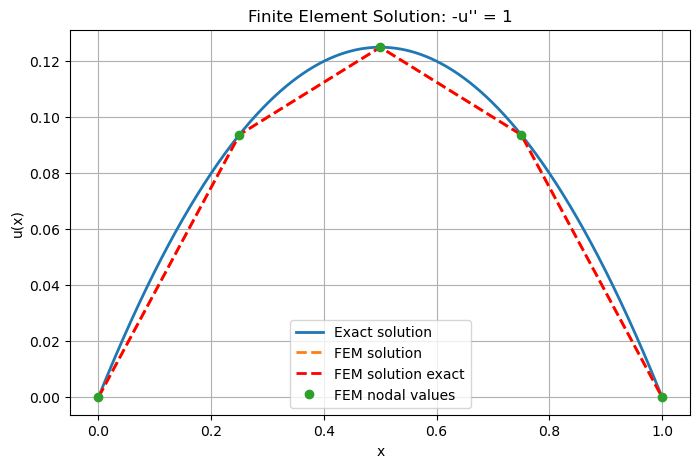

In [26]:
# Problem definition
n = 4
a, b = 0, 1
u_a = 0
u_b = 0
f = lambda x: np.ones_like(x)
u_exact = lambda x: 0.5 * x * (1 - x)
xe = np.linspace(a, b, 1000)

# Mesh and function values
x = np.linspace(a, b, n + 1)
f_vals = f(x)

# Assemble the full system
A = stiffness_assembler_1d(x)
rhs = load_assembler_1d(x, f_vals)
rhs_exact = load_assembler_1d_exact(x, f)

# Apply homogeneous Dirichlet boundary conditions
A_interior = A[1:-1, 1:-1]
rhs_interior = rhs[1:-1]
rhs_exact_interior = rhs_exact[1:-1]

# Solve for the interior coefficients
xi = np.linalg.solve(A_interior, rhs_interior)
xi_exact = np.linalg.solve(A_interior, rhs_exact_interior)

u_h = np.zeros(n + 1)
u_h_exact = np.zeros(n + 1)
u_h[1:-1] = xi
u_h_exact[1:-1] = xi_exact

u_h[0] = u_a
u_h[-1] = u_b
u_h_exact[0] = u_a
u_h_exact[-1] = u_b

# Plot both solutions and the exact solution
xe, u_hI = interpolant_1d(x, u_h, xe)
xe, u_hI_exact = interpolant_1d(x, u_h_exact, xe)
u_exact_eval = u_exact(xe)

plt.figure(figsize=(8, 5))
plt.plot(xe, u_exact_eval, label="Exact solution", linewidth=2)
plt.plot(xe, u_hI, "--", label="FEM solution", linewidth=2)
plt.plot(xe, u_hI_exact, "r--", label="FEM solution exact", linewidth=2)
plt.plot(x, u_h, "o", label="FEM nodal values")

plt.xlabel("x")
plt.ylabel("u(x)")
plt.title("Finite Element Solution: -u'' = 1")
plt.grid(True)
plt.legend()
plt.show()




### 2. Error Analysis

#### 2.1 Galerkin Orthogonality (Theorem 2.1)
This is the most important property of the FEM solution. The error $e = u - u_h$ is **"orthogonal"** to the approximation space $V_{h,0}$ in the integral-of-derivatives sense.

* **Theorem:** $$\int_I (u - u_h)' v' \,dx = 0 \quad \forall v \in V_{h,0}$$

* **Proof:** The weak form holds for $u$: $\int_I u'v' \,dx = \int_I fv \,dx$. The FEM form holds for $u_h$: $\int_I u_h'v' \,dx = \int_I fv \,dx$. Subtracting the two equations gives the result.

#### 2.2 Best Approximation (Theorem 2.2)
Galerkin orthogonality implies that $u_h$ is the **best possible approximation** of $u$ from the space $V_{h,0}$ when measured in the "energy norm" ($||v'||_{L_2}$).

* **Theorem:** $$||(u - u_h)'||_{L_2} \le ||(u - v)'||_{L_2} \quad \forall v \in V_{h,0}$$

* This means no other function in $V_{h,0}$ (including the interpolant $\pi_h u$) can get closer to $u$ in this norm.

#### 2.3 A Priori Error Estimate (Theorem 2.3)
This theorem gives a bound on the error in terms of the (unknown) exact solution $u$ and the mesh size $h$.

* **Theorem:** $$||(u - u_h)'||_{L_2} \le C h ||u''||_{L_2}$$

* This shows the error in the *derivative* converges linearly as the mesh size $h$ goes to zero.



---


### 3. Generalization: Variable Coefficients and Robin BCs

Physical models, like heat transfer $-(AkT')' = f$ or an elastic bar $-(AEu')' = f$, lead to a more general problem with a variable coefficient $a(x)$:

* $-(a(x)u')' = f(x) \quad \text{for } x \in I = [0, L]$

We also introduce more general **Robin boundary conditions**:

* $a(0)u'(0) = \kappa_0(u(0) - g_0)$

* $-a(L)u'(L) = \kappa_L(u(L) - g_L)$


#### 3.1 Variational Formulation
We repeat the process: multiply by $v$ and integrate by parts.
$$\int_I fv \,dx = -\int_I (au')'v \,dx = \int_I au'v' \,dx - [au'v]_0^L$$
$$\int_I fv \,dx = \int_I au'v' \,dx - (a(L)u'(L)v(L) - a(0)u'(0)v(0))$$

Now, we *substitute* the Robin BCs into the boundary terms:
$$\int_I fv \,dx = \int_I au'v' \,dx - (-\kappa_L(u(L)-g_L)v(L) - \kappa_0(u(0)-g_0)v(0))$$

We rearrange this to put all terms with the unknown $u$ on the left and all known data ($f, g_0, g_L$) on the right:
**Find $u \in V$ such that:**
$$\int_I au'v' \,dx + \kappa_L u(L)v(L) + \kappa_0 u(0)v(0) = \int_I fv \,dx + \kappa_L g_L v(L) + \kappa_0 g_0 v(0) \quad \forall v \in V$$

Note: We now use the space $V$, not $V_0$, because $u$ and $v$ are no longer required to be zero at the boundaries.


#### 3.2 FEM and the New Linear System
We discretize by replacing $V$ with $V_h$ (the full space of $n+1$ hat functions, $\{\phi_j\}_{j=0}^n$). The ansatz is now $$u_h = \sum_{j=0}^n \xi_j \phi_j.$$

Plugging this into the variational form and testing against each $\phi_i$ (for $i=0, ..., n$) yields a new $(n+1) \times (n+1)$ linear system:
$$(A + R)\xi = b + r$$

This system is composed of four parts:

1.  **Stiffness Matrix ($A$):** $$A_{ij} = \int_I a(x) \phi_j' \phi_i' \,dx$$

2.  **Boundary Matrix ($R$):** $$R_{ij} = \kappa_L \phi_j(L)\phi_i(L) + \kappa_0 \phi_j(0)\phi_i(0)$$
    This matrix is all zeros except $R_{00} = \kappa_0$ and $R_{nn} = \kappa_L$

3.  **Load Vector ($b$):** $$b_i = \int_I f(x) \phi_i(x) \,dx$$

4.  **Boundary Vector ($r$):** $$r_i = \kappa_L g_L \phi_i(L) + \kappa_0 g_0 \phi_i(0)$$
    This vector is all zeros except $r_0 = \kappa_0 g_0$ and $r_n = \kappa_L g_L$

The matrix $A+R$ is assembled element-by-element.

---
